#. First we important library 

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.arima.model import ARIMA, ARIMAResults
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX  



# hide warnings
import warnings
warnings.simplefilter("ignore")

from sklearn.metrics import mean_squared_error, mean_absolute_error
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True

print("Libraries imported successfully.")

Libraries imported successfully.


DATA LOADING AND INSPECTION

In [135]:
df = pd.read_csv('data_file/GlobalLandTemperaturesByCity.csv')
df

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1743-11-01,6.068,1.737,Århus,Denmark,57.05N,10.33E
1,1743-12-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
2,1744-01-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
3,1744-02-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
4,1744-03-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
...,...,...,...,...,...,...,...
8599207,2013-05-01,11.464,0.236,Zwolle,Netherlands,52.24N,5.26E
8599208,2013-06-01,15.043,0.261,Zwolle,Netherlands,52.24N,5.26E
8599209,2013-07-01,18.775,0.193,Zwolle,Netherlands,52.24N,5.26E
8599210,2013-08-01,18.025,0.298,Zwolle,Netherlands,52.24N,5.26E


In [136]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8599212 entries, 0 to 8599211
Data columns (total 7 columns):
 #   Column                         Dtype  
---  ------                         -----  
 0   dt                             str    
 1   AverageTemperature             float64
 2   AverageTemperatureUncertainty  float64
 3   City                           str    
 4   Country                        str    
 5   Latitude                       str    
 6   Longitude                      str    
dtypes: float64(2), str(5)
memory usage: 459.2 MB


##change the dt as proper datetime

In [137]:
# convert first column to DateTime format
#df['dt'] = pd.to_datetime(df['dt'])
df['dt'] = pd.to_datetime(df['dt'])
# set first column (dt) as the index column
df.index = df['dt']
del df['dt']

# dropping unnecessary columns and combining City and Country
df = df.drop(columns=["AverageTemperatureUncertainty", "Latitude", "Longitude"])
df["City"] = df["City"] + ", " + df["Country"]
df = df.drop(columns="Country")

# removing all rows with NaN values
df = df.dropna()

# get list of all cities in dataset
cities = set(df.City)

In [138]:
# check stationarity in time series data of a given city

def check_stationarity(city_df):
    # method1: plot the time series to check for trend and seasonality
    city_df.plot(figsize=(10, 10))
    
    # method 2: check if histogram fits a Gaussian Curve, then split data into two parts, calculate means and variances and see if they vary
    city_df.hist(figsize=(10, 10))
    plt.show()
    
    X = city_df["AverageTemperature"].values
    split = int(len(X) / 2)
    X1, X2 = X[0:split], X[split:]
    mean1, mean2 = X1.mean(), X2.mean()
    var1, var2 = X1.var(), X2.var()
    print('mean1=%f, mean2=%f' % (mean1, mean2))
    print('variance1=%f, variance2=%f' % (var1, var2))
    
    # if corresponding means and variances differ slightly (by less than 10), we consider that the time series might be stationary
    if (abs(mean1-mean2) <= 10 and abs(var1-var2) <= 10):
        print("Time Series may be Stationary, since means and variances vary only slightly.\n")
    else:
        print("Time Series may NOT be Stationary, since means and variances vary significantly.\n")
        
    # method3: statistical test (Augmented Dickey-Fuller statistic)
    print("Performing Augmented Dickey-Fuller Test to confirm stationarity...")
    
    result = adfuller(X)
    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    
    p = result[1]
    if (p > 0.05):
        print("Time Series is NOT Stationary, since p-value > 0.05")
        city_df = city_df.diff()  # differencing to make data stationary
        return False
    else:
        print("Time Series is Stationary, since p-value <= 0.05")
        return True

['A Coruña, Spain', 'Aachen, Germany', 'Aalborg, Denmark', 'Aba, Nigeria', 'Abadan, Iran', 'Abakaliki, Nigeria', 'Abakan, Russia', 'Abbotsford, Canada', "Abengourou, Côte D'Ivoire", 'Abeokuta, Nigeria', 'Aberdeen, United Kingdom', 'Abha, Saudi Arabia', "Abidjan, Côte D'Ivoire", 'Abiko, Japan', 'Abilene, United States', 'Abohar, India', 'Abomey Calavi, Benin', 'Abu Dhabi, United Arab Emirates', 'Abuja, Nigeria', 'Acapulco, Mexico', 'Acarigua, Venezuela', 'Accra, Ghana', 'Achalpur, India', 'Acheng, China', 'Achinsk, Russia', 'Acuña, Mexico', 'Adana, Turkey', 'Addis Abeba, Ethiopia', 'Adelaide, Australia', 'Aden, Yemen', 'Adilabad, India', 'Adiwerna, Indonesia', 'Adoni, India', 'Afyonkarahisar, Turkey', 'Agadir, Morocco', 'Agartala, India', "Agboville, Côte D'Ivoire", 'Ageo, Japan', 'Agra, India', 'Aguascalientes, Mexico', 'Ahmadabad, India', 'Ahmadnagar, India', 'Ahmadpur East, Pakistan', 'Ahvaz, Iran', 'Aix En Provence, France', 'Aizawl, India', 'Ajdabiya, Libya', 'Ajmer, India', 'Akash

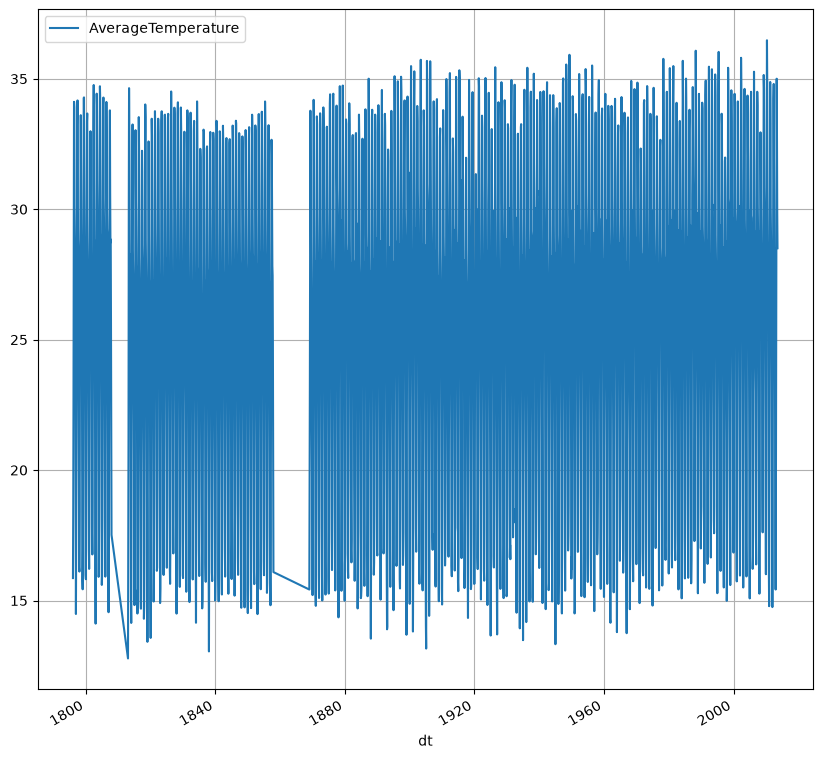

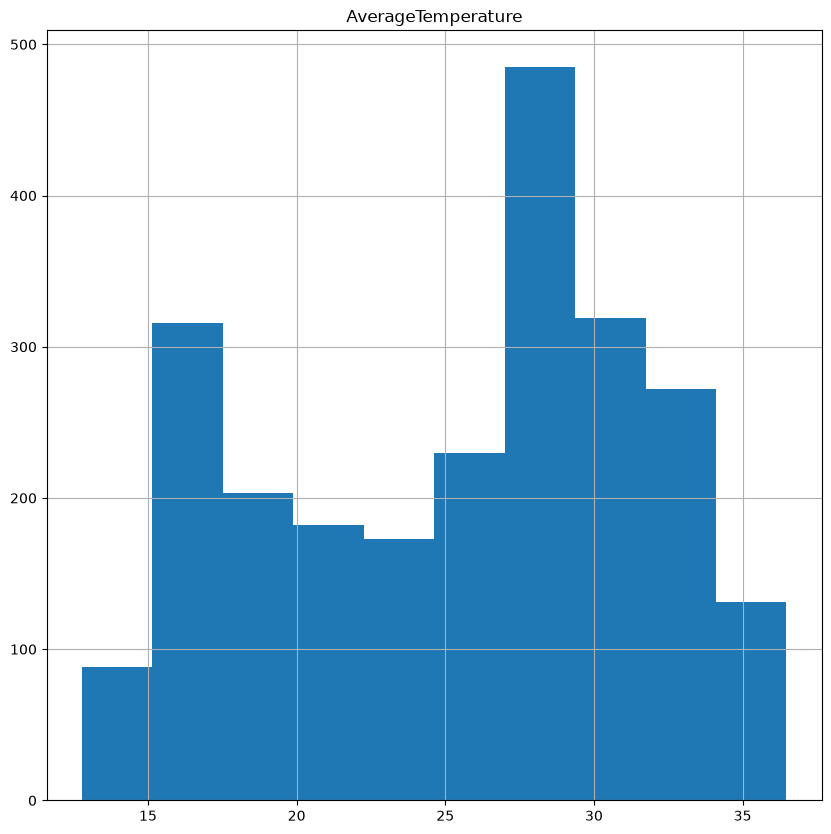

mean1=25.101356, mean2=25.684517
variance1=37.744871, variance2=37.531576
Time Series may be Stationary, since means and variances vary only slightly.

Performing Augmented Dickey-Fuller Test to confirm stationarity...
ADF Statistic: -5.732217
p-value: 0.000001
Time Series is Stationary, since p-value <= 0.05


True

In [139]:
print(sorted(df['City'].unique()))
city = 'Ajmer, India'  # Or any city from the printed list
df_city = df[df['City'] == city].drop(columns='City')
# 2. Fill the missing gaps using linear interpolation (instead of dropping them)
df_city['AverageTemperature'] = df_city['AverageTemperature'].interpolate(method='linear')

# 3. Run the stationarity check on the properly continuous data
check_stationarity(df_city)

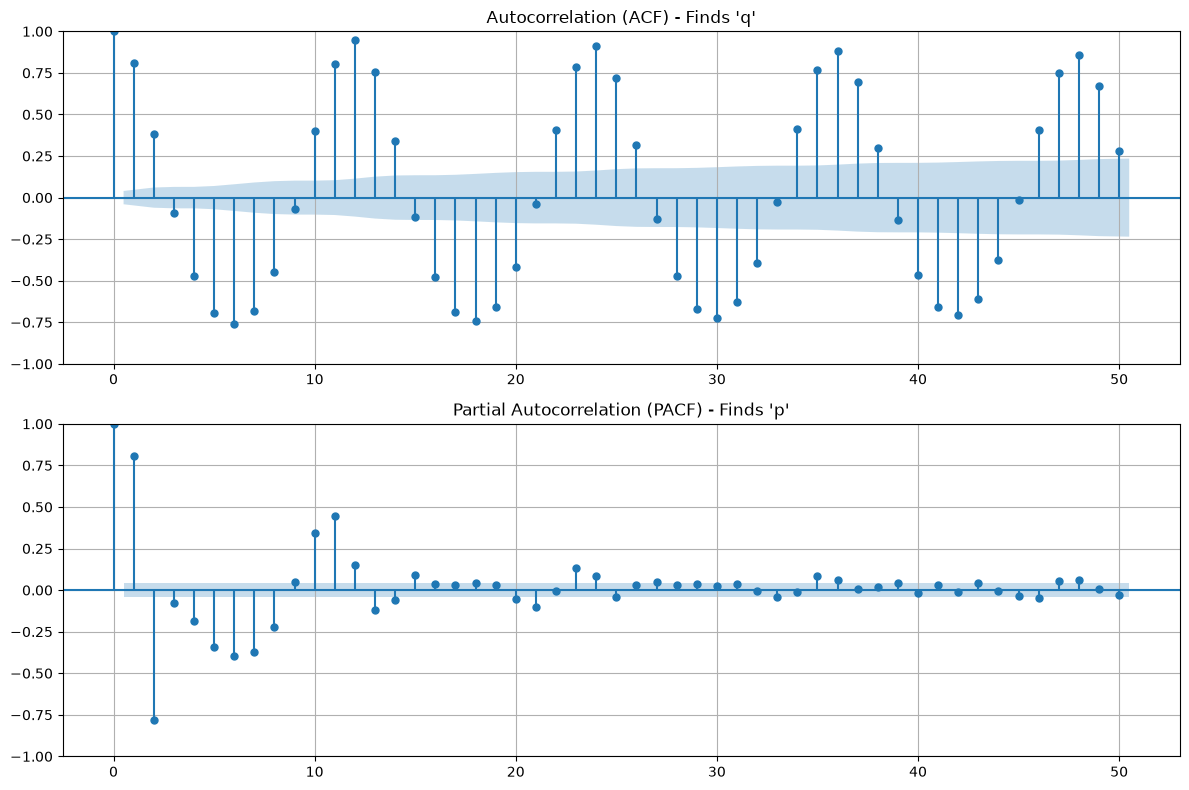

In [140]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# Plot the Autocorrelation Function (ACF)
plot_acf(df_city['AverageTemperature'], lags=50, ax=ax1)
ax1.set_title("Autocorrelation (ACF) - Finds 'q'")

# Plot the Partial Autocorrelation Function (PACF)
plot_pacf(df_city['AverageTemperature'], lags=50, ax=ax2)
ax2.set_title("Partial Autocorrelation (PACF) - Finds 'p'")

plt.tight_layout()
plt.show()

In [141]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Define the SARIMA model parameters
# order=(p, d, q) -> p=1 (from PACF), d=0 (stationary), q=1 (starting estimate)
# seasonal_order=(P, D, Q, s) -> s=12 specifies the 12-month repeating cycle
model = SARIMAX(df_city['AverageTemperature'], 
                order=(1, 0, 1), 
                seasonal_order=(1, 1, 1, 12))

# 2. Train (fit) the model
print("Training model... this might take a few seconds.")
results = model.fit()

# 3. Print the summary of the trained model
print(results.summary())

Training model... this might take a few seconds.
                                     SARIMAX Results                                      
Dep. Variable:                 AverageTemperature   No. Observations:                 2399
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 12)   Log Likelihood               -4426.558
Date:                            Sun, 11 Oct 2026   AIC                           8863.115
Time:                                    13:15:30   BIC                           8892.004
Sample:                                         0   HQIC                          8873.628
                                           - 2399                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4466      0.019     23.509      0.000       0.40

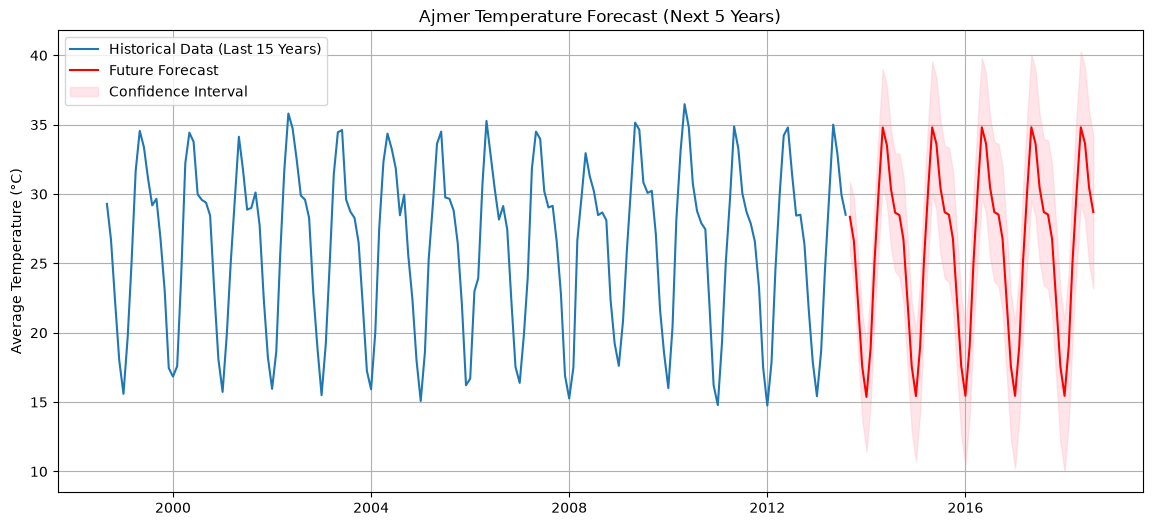

In [142]:
# 1. Force the index to have a strict 'Month Start' (MS) frequency
df_city = df_city.asfreq('MS')

# 2. Re-apply interpolation just in case forcing the frequency exposed new gaps
df_city['AverageTemperature'] = df_city['AverageTemperature'].interpolate(method='linear')

# 3. Retrain the SARIMA model on the properly sequenced data
from statsmodels.tsa.statespace.sarimax import SARIMAX
model = SARIMAX(df_city['AverageTemperature'], 
                order=(1, 0, 1), 
                seasonal_order=(1, 1, 1, 12))
results = model.fit(disp=False) # disp=False hides the training text wal
# 1. Generate a forecast for the next 60 months (5 years)
forecast = results.get_forecast(steps=60)
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

# 2. Set up the graph
plt.figure(figsize=(14, 6))

# 3. Plot the historical data (just the last 15 years so the graph isn't too crowded)
plt.plot(df_city.index[-180:], df_city['AverageTemperature'].iloc[-180:], label='Historical Data (Last 15 Years)', color='tab:blue')

# 4. Plot the red forecast line
plt.plot(forecast_mean.index, forecast_mean, color='red', label='Future Forecast')

# 5. Add a pink shaded confidence interval showing the upper and lower bounds of the prediction
plt.fill_between(confidence_intervals.index, 
                 confidence_intervals.iloc[:, 0], 
                 confidence_intervals.iloc[:, 1], color='pink', alpha=0.4, label='Confidence Interval')

plt.title('Ajmer Temperature Forecast (Next 5 Years)')
plt.ylabel('Average Temperature (°C)')
plt.legend()
plt.grid(True)
plt.savefig('sarima_forecast.png', bbox_inches='tight')
plt.show()

### 5-Year Temperature Forecast (SARIMA)
![SARIMA Forecast](sarima_forecast.png)

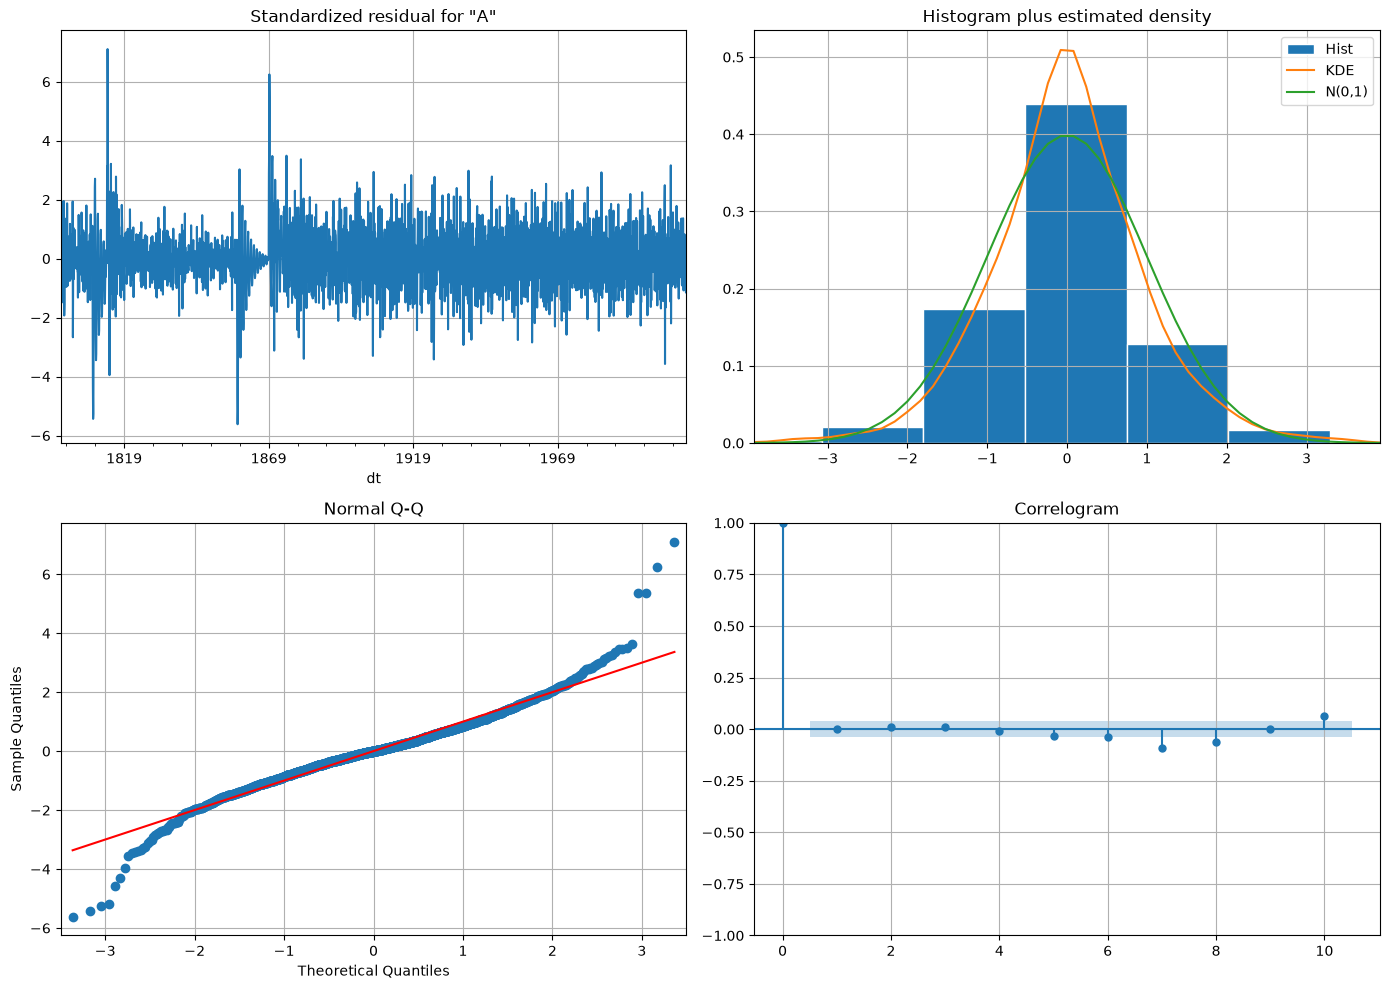

In [143]:
import matplotlib.pyplot as plt

# Generate the 4 standard mathematical diagnostic plots for SARIMA
fig = results.plot_diagnostics(figsize=(14, 10))
plt.tight_layout()
plt.savefig('sarima_diagnostics.png', bbox_inches='tight')
plt.show()


In [144]:
pip install prophet

Note: you may need to restart the kernel to use updated packages.


13:15:33 - cmdstanpy - INFO - Chain [1] start processing


Training Facebook Prophet model...


13:15:33 - cmdstanpy - INFO - Chain [1] done processing


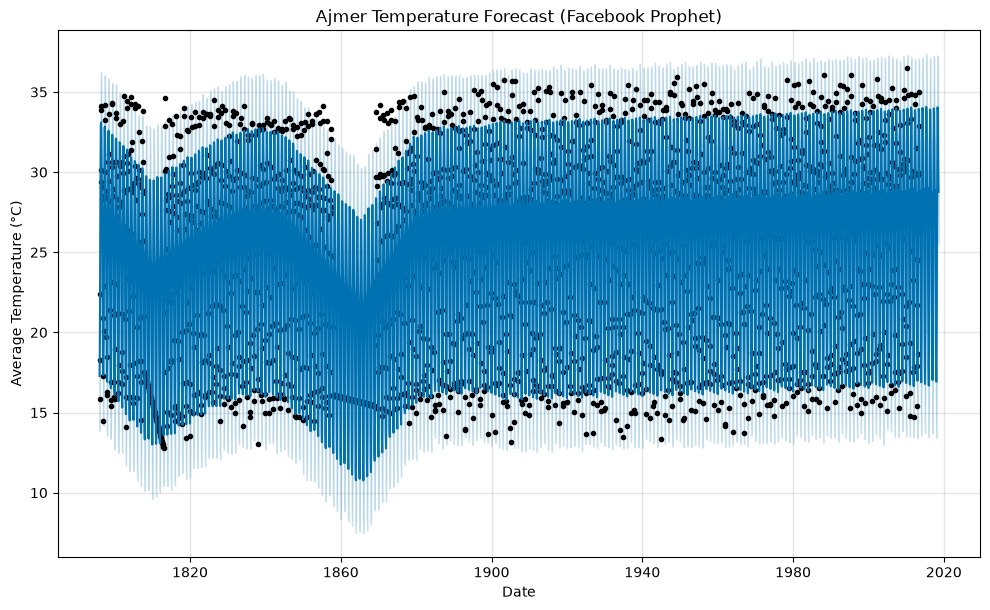

In [145]:
# You may need to run '!pip install prophet' in a cell first if you haven't installed it
from prophet import Prophet

# 1. Reset the index so the dates become a normal column again
prophet_df = df_city.reset_index()

# 2. Rename the columns exactly as Prophet expects ('ds' and 'y')
prophet_df.columns = ['ds', 'y']

# 3. Initialize the model and train it on the historical data
print("Training Facebook Prophet model...")
m = Prophet()
m.fit(prophet_df)

# 4. Ask Prophet to generate a timeline for the next 60 months (5 years)
future = m.make_future_dataframe(periods=60, freq='MS')

# 5. Predict the temperatures for that future timeline
forecast_prophet = m.predict(future)

# 6. Use Prophet's built-in plotting tool to see the results
fig = m.plot(forecast_prophet)
import matplotlib.pyplot as plt
plt.title('Ajmer Temperature Forecast (Facebook Prophet)')
plt.ylabel('Average Temperature (°C)')
plt.xlabel('Date')
fig.savefig('prophet_forecast.png', bbox_inches='tight')
plt.show()


In [146]:
# Exporting the Prophet forecast to CSV
forecast_prophet[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(60).to_csv('ajmer_5yr_temperature_forecast.csv', index=False)
